First five rows of dataset:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 r

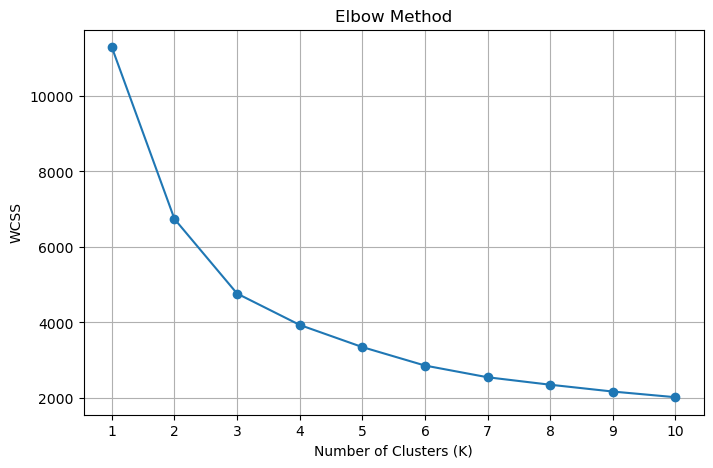


Optimal Number of Clusters: 3

K-Means Cluster Counts:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64


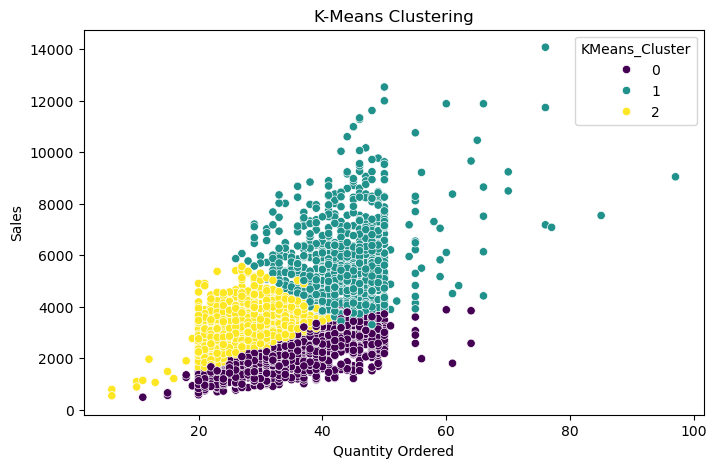


Hierarchical Cluster Counts:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


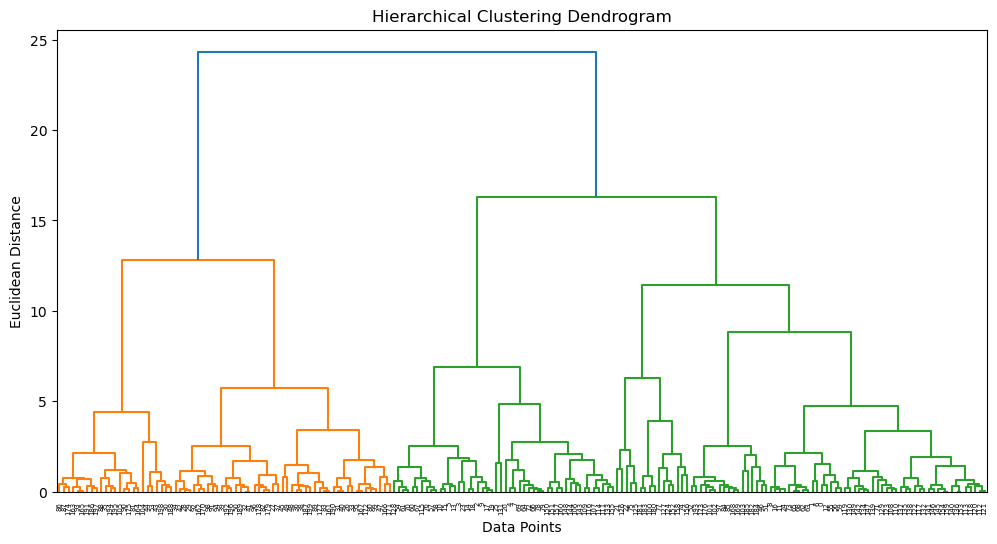

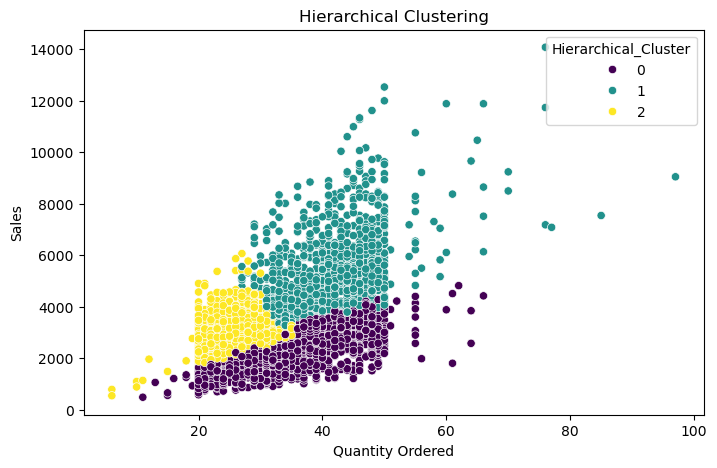


Final Dataset:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  KMeans_Cluster  \
0               30      95.70  2871.00    95               2   
1               34      81.35  2765.90    95               2   
2               41      94.74  3884.34    95               1   
3               45      83.26  3746.70    95               1   
4               49     100.00  5205.27    95               1   

   Hierarchical_Cluster  
0                     2  
1                     2  
2                     0  
3                     0  
4                     1  


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# 1. Load dataset
df = pd.read_csv("sales_data_sample.csv", encoding="unicode_escape")

print("First five rows of dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# 2. Select numerical features
features = ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]
X = df[features].copy()

# 3. Handle missing values
X = X.fillna(X.median())

# 4. Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Elbow Method to find optimal K
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# 6. Select optimal number of clusters
optimal_k = 3

print("\nOptimal Number of Clusters:", optimal_k)

# 7. Apply K-Means Clustering
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means Cluster Counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())

# 8. Visualize K-Means Clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df["QUANTITYORDERED"],
    y=df["SALES"],
    hue=df["KMeans_Cluster"],
    palette="viridis"
)

plt.title("K-Means Clustering")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

# 9. Apply Hierarchical Clustering
hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage="ward"
)

df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("\nHierarchical Cluster Counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

# 10. Generate Dendrogram
# Use a sample of 200 records for clear visualization
linked = linkage(X_scaled[:200], method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linked)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

# 11. Visualize Hierarchical Clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df["QUANTITYORDERED"],
    y=df["SALES"],
    hue=df["Hierarchical_Cluster"],
    palette="viridis"
)

plt.title("Hierarchical Clustering")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

# 12. Display final dataset with cluster labels
print("\nFinal Dataset:")
print(df[features + ["KMeans_Cluster", "Hierarchical_Cluster"]].head())
